# **Notebook 2: Data Preparation**
## Assignment: Hybrid RAG & Fine-Tuning for Customer Support
---

### TO-DO: Before Running This Notebook

**Files you NEED:**
- [ ] `sampled_data.csv` — Created by Notebook 1
- [ ] `corporate_policies/` folder with `.md` SOP files
- [ ] Internet access (to download the tokenizer)

**Files this notebook will CREATE:**
- [ ] `./tokenized_train/`, `./tokenized_valid/`, `./tokenized_test/` — HuggingFace datasets _(Required by NB6)_
- [ ] `df_test.csv` — Test set with readable text + labels _(Required by NB5 and NB7)_

---

## **Stage 2: Data Preparation**
### **Task 2.1: Clean and Validate Dataset**

#### **2.1.1 Remove Duplicate and Invalid Records [2 marks]**
**The Task:** Identify and remove duplicate records using normalised deduplication (lowercase + strip before comparison), plus any invalid, incomplete, or corrupted records.

**Hints & Tips:**
* Load `sampled_data.csv` from Notebook 1 first.
* Normalised dedup: create a temporary `_norm` column = `instruction.str.lower().str.strip()`, drop duplicates on it, then drop the helper column.
* Check for nulls in `instruction`, `intent`, and `category` — drop rows missing any of these targets.
* Print the number of rows removed so the cleaning is auditable.

**Why we are doing it:** To prevent degraded training from redundant or broken records, and to stop near-duplicates leaking across train/test splits later.
**How we are doing it:** Pandas normalised deduplication and null filtering.

**Learner Inference:** Exact-match dedup misses `"Where is my order?"` vs `"where is my order?"`. Normalising first catches these and keeps your splits clean.

In [1]:
# YOUR CODE HERE
import pandas as pd

# 1. Load exported data from Notebook 1
df_raw = pd.read_csv("sampled_data.csv")
initial_count = len(df_raw)
print(f"Initial raw rows loaded: {initial_count:,}")

# 2. Check and remove nulls in essential columns
df_clean = df_raw.dropna(subset=['instruction', 'intent', 'category']).copy()
null_removed = initial_count - len(df_clean)

# 3. Perform Normalised Deduplication
# Create temporary normalized column (lowercased + stripped spaces)
df_clean['_norm'] = df_clean['instruction'].astype(str).str.lower().str.strip()

# Count duplicates before dropping
norm_duplicates_count = df_clean.duplicated(subset=['_norm']).sum()

# Drop duplicates keeping first occurrence
df_clean = df_clean.drop_duplicates(subset=['_norm'], keep='first').copy()

# Drop helper column
df_clean.drop(columns=['_norm'], inplace=True)

final_count = len(df_clean)
total_removed = initial_count - final_count

print(f"\n--- Data Cleaning Audit Summary ---")
print(f"Null records dropped              : {null_removed}")
print(f"Near-duplicates dropped (Normalised): {norm_duplicates_count}")
print(f"Total invalid/duplicate records removed: {total_removed}")
print(f"Cleaned dataset row count         : {final_count:,}")

Initial raw rows loaded: 3,902

--- Data Cleaning Audit Summary ---
Null records dropped              : 0
Near-duplicates dropped (Normalised): 0
Total invalid/duplicate records removed: 0
Cleaned dataset row count         : 3,902


#### **2.1.2 Standardise Dataset Formatting [2 marks]**
**The Task:** Clean the strings inside `instruction`, `intent`, and `category` by stripping whitespace and enforcing uniform casing (intents = lower, categories = upper).

**Hints & Tips:**
* Use Pandas `.str.strip()`, `.str.lower()`, `.str.upper()`.
* Always strip whitespace BEFORE lowering — trailing spaces survive `.lower()`.
* Standardised casing prevents the model treating "Refund" and "refund" as different classes.

**Why we are doing it:** To ensure raw strings are perfectly standardised before injecting them into prompt templates.
**How we are doing it:** Pandas string manipulation.

**Learner Inference:** Standardising capitalisation prevents the model from treating the same intent written two ways as two separate classes.

In [2]:
# YOUR CODE HERE
# 1. Standardise text formatting
# Strip trailing/leading spaces FIRST, then enforce casing rules
df_clean['instruction'] = df_clean['instruction'].astype(str).str.strip()
df_clean['intent'] = df_clean['intent'].astype(str).str.strip().str.lower()
df_clean['category'] = df_clean['category'].astype(str).str.strip().str.upper()

# 2. Inspect standardized output sample
print("--- Standardized Dataset Sample ---")
print(df_clean[['instruction', 'intent', 'category']].head(5))

print(f"\nUnique Intents Count   : {df_clean['intent'].nunique()}")
print(f"Unique Categories Count: {df_clean['category'].nunique()}")

--- Standardized Dataset Sample ---
                                         instruction  \
0                   I can't talk with  a human agent   
1  I have got to locate hte bills from {{Person N...   
2  I cannot pay, help me to inform of a problem w...   
3           I want help speaking to customer service   
4           I try to see th accepted payment options   

                     intent category  
0       contact_human_agent  CONTACT  
1             check_invoice  INVOICE  
2             payment_issue  PAYMENT  
3  contact_customer_service  CONTACT  
4     check_payment_methods  PAYMENT  

Unique Intents Count   : 27
Unique Categories Count: 11


### **Task 2.2: Create Instruction-Tuning Dataset**

#### **2.2.1 Transform Records into Instruction Format [2 marks]**
**The Task:** Wrap the raw instructions and targets into a standardized `ChatML` format, forcing the assistant's response to be a strict JSON string containing the `intent` and `category`.

**Hints & Tips:**
* Use the Qwen tokenizer's `apply_chat_template(tokenize=False)`.
* The target JSON is `{"intent": "...", "category": "..."}` — built via `json.dumps()`.

**Model Selection:**
* **Qwen/Qwen2.5-1.5B-Instruct** (recommended) — fits T4, strong instruction following.
* **TinyLlama-1.1B-Chat** — lighter but weaker at structured output.
* **Llama-3-8B-Instruct** — best quality, needs >16GB VRAM even in 4-bit.
* Whatever you pick, set `MODEL_ID` here and in ALL later notebooks.

**Learner Inference:** Formatting the target as JSON establishes the exact structural rules the LoRA model learns to mimic in Stage 4.

In [4]:
# YOUR CODE HERE
import json
from transformers import AutoTokenizer

# 1. Define MODEL_ID (Qwen2.5-1.5B-Instruct recommended)
MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"

# 2. Load tokenizer from HuggingFace
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True)

# Set padding token to EOS token if not explicitly defined
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# 3. Define System Prompt instructing strict JSON generation
SYSTEM_PROMPT = (
    "You are a customer support intent router. Analyze the user's inquiry "
    "and reply with a JSON object containing 'intent' and 'category'."
)

# 4. Transform raw records into standardized ChatML strings
formatted_prompts = []

for idx, row in df_clean.iterrows():
    # Build strict JSON target string
    target_json = json.dumps({
        "intent": row['intent'],
        "category": row['category']
    })
    
    # Construct ChatML conversation structure
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": row['instruction']},
        {"role": "assistant", "content": target_json}
    ]
    
    # Apply chat template to generate the raw text prompt (tokenize=False returns string)
    chatml_text = tokenizer.apply_chat_template(messages, tokenize=False)
    formatted_prompts.append(chatml_text)

# Assign formatted text back to dataframe
df_clean['formatted_text'] = formatted_prompts

# 5. Display a sample formatted prompt
print("Successfully formatted records into ChatML format.")
print("\n--- Example ChatML Formatted Prompt ---")
print(df_clean['formatted_text'].iloc[0])

Successfully formatted records into ChatML format.

--- Example ChatML Formatted Prompt ---
<|im_start|>system
You are a customer support intent router. Analyze the user's inquiry and reply with a JSON object containing 'intent' and 'category'.<|im_end|>
<|im_start|>user
I can't talk with  a human agent<|im_end|>
<|im_start|>assistant
{"intent": "contact_human_agent", "category": "CONTACT"}<|im_end|>



In [23]:
# print(df_clean.head())
print(target_json)
# print(formatted_prompts)
chatml_text
df_clean.tail()

{"intent": "payment_issue", "category": "PAYMENT"}


,flags,instruction,category,intent,response,formatted_text
3897,BL,I want to check in which situations can I ask ...,REFUND,check_refund_policy,I'll take care of it! I can understand your ne...,<|im_start|>system\nYou are a customer support...
3898,BILQZ,how cab i find information about my key recovery,ACCOUNT,recover_password,I'm here to assist you in finding information ...,<|im_start|>system\nYou are a customer support...
3899,BLM,help me to acquire some of your article,ORDER,place_order,I'm delighted to assist you in acquiring some ...,<|im_start|>system\nYou are a customer support...
3900,BLMZ,see my blls from {{Person Name}},INVOICE,check_invoice,I get it the importance of gaining access to y...,<|im_start|>system\nYou are a customer support...
3901,BILMQ,where can i notify of troubles with payments,PAYMENT,payment_issue,I'm here to help you with any troubles you're ...,<|im_start|>system\nYou are a customer support...


#### **2.2.2 Validate Instruction Templates [2 marks]**
**The Task:** Extract the assistant's portion of the generated ChatML string and parse it with `json.loads()` to verify structural integrity.

**Hints & Tips:**
* Split the string by `<|im_start|>assistant` and parse what follows.
* If this throws `JSONDecodeError`, your formatting in 2.2.1 is broken — fix before training.
* Validate several samples, not just the first.

**Learner Inference:** A JSONDecodeError here means the model would learn broken syntax. Catching it now saves a failed training run.

In [24]:
# YOUR CODE HERE
import json
import random

def validate_chatml_assistant_json(chatml_text):
    """
    Extracts the assistant response block from a ChatML string 
    and validates its JSON structure using json.loads().
    """
    # 1. Check if the prompt contains the assistant header tag
    if "<|im_start|>assistant" not in chatml_text:
        return False, "Missing '<|im_start|>assistant' tag in ChatML string."
    
    # 2. Extract text following '<|im_start|>assistant'
    assistant_section = chatml_text.split("<|im_start|>assistant\n")[-1]
    
    # 3. Strip out the closing ChatML end-of-message tag if present
    assistant_json_str = assistant_section.split("<|im_end|>")[0].strip()
    
    # 4. Attempt to parse string as JSON
    try:
        parsed_data = json.loads(assistant_json_str)
        
        # Verify required keys exist
        if "intent" in parsed_data and "category" in parsed_data:
            return True, parsed_data
        else:
            return False, f"JSON parsed, but missing 'intent' or 'category' keys: {parsed_data}"
            
    except json.JSONDecodeError as e:
        return False, f"JSONDecodeError: {str(e)} | Raw String: '{assistant_json_str}'"

# --- Validate Across Multiple Random Samples ---
# Select up to 50 random records across the dataset to ensure robust checking
sample_size = min(50, len(df_clean))
random_indices = random.sample(range(len(df_clean)), sample_size)

passed_count = 0
failed_count = 0

print(f"--- Validating {sample_size} Instruction Templates ---")

for idx in random_indices:
    sample_text = df_clean['formatted_text'].iloc[idx]
    is_valid, result = validate_chatml_assistant_json(sample_text)
    
    if is_valid:
        passed_count += 1
    else:
        failed_count += 1
        print(f" Error at row {idx}: {result}")

print("\n--- Validation Summary ---")
print(f"Total Samples Tested : {sample_size}")
print(f"Passed Validations   : {passed_count} / {sample_size}")
print(f"Failed Validations   : {failed_count} / {sample_size}")

if failed_count == 0:
    print("\n All samples validated successfully! Target JSON structures are 100% compliant.")
else:
    print("\n Validation failures detected. Re-check Task 2.2.1 before proceeding to tokenization.")

--- Validating 50 Instruction Templates ---

--- Validation Summary ---
Total Samples Tested : 50
Passed Validations   : 50 / 50
Failed Validations   : 0 / 50

 All samples validated successfully! Target JSON structures are 100% compliant.


### **Task 2.3: Engineer Training and Retrieval Data**

#### **2.3.1 Tokenise Dataset [2 marks]**
**The Task:** Convert text sequences into tensor IDs and apply `-100` masking to padding tokens in the `labels` array.

**Hints & Tips:**
* If a token equals `tokenizer.pad_token_id`, replace it with `-100` in labels.
* `-100` is PyTorch's ignore index — the loss skips these tokens.

**Parameter Tuning:**
* `max_length`: `128` (fast, fits most Bitext prompts), `256` (safer if truncation seen), `64` (too aggressive).

**Learner Inference:** Masking isolates the loss — the model is penalised for wrong JSON, not for padding.

In [25]:
# YOUR CODE HERE
import torch

# 1. Configuration parameters
MAX_LENGTH = 128

print(f"Tokenizing dataset with MAX_LENGTH={MAX_LENGTH}...")

# 2. Tokenize the ChatML formatted text strings in batch
# Padding and truncation prepare fixed-size matrix dimensions
encoded_inputs = tokenizer(
    df_clean['formatted_text'].tolist(),
    max_length=MAX_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="pt"  # Return PyTorch tensors
)

# 3. Create labels array (clone input_ids)
# In standard Causal LM training, labels start as a copy of input_ids
labels = encoded_inputs['input_ids'].clone()

# 4. Apply -100 masking to all padding token positions
# PyTorch CrossEntropyLoss ignores any position marked with -100
labels[labels == tokenizer.pad_token_id] = -100

# 5. Store processed tensors in a structured dictionary
tokenized_dataset = {
    'input_ids': encoded_inputs['input_ids'],
    'attention_mask': encoded_inputs['attention_mask'],
    'labels': labels
}

# 6. Sanity check: verify shape and inspect masked label tokens
print("\nTokenization and -100 Masking complete!")
print(f"Input IDs shape      : {tokenized_dataset['input_ids'].shape}")
print(f"Attention Mask shape : {tokenized_dataset['attention_mask'].shape}")
print(f"Labels shape          : {tokenized_dataset['labels'].shape}")

# Print first 20 tokens of input_ids vs labels from the first row to visualize -100 replacing pad tokens
sample_pad_idx = (tokenized_dataset['input_ids'][0] == tokenizer.pad_token_id).nonzero(as_tuple=True)[0]
if len(sample_pad_idx) > 0:
    first_pad_pos = sample_pad_idx[0].item()
    print(f"\n--- Verification Sample (Row 0 around padding boundary at position {first_pad_pos}) ---")
    print(f"Raw Input IDs [pos {first_pad_pos}:] : {tokenized_dataset['input_ids'][0][first_pad_pos:first_pad_pos+5].tolist()}")
    print(f"Masked Labels [pos {first_pad_pos}:] : {tokenized_dataset['labels'][0][first_pad_pos:first_pad_pos+5].tolist()}")

Tokenizing dataset with MAX_LENGTH=128...

Tokenization and -100 Masking complete!
Input IDs shape      : torch.Size([3902, 128])
Attention Mask shape : torch.Size([3902, 128])
Labels shape          : torch.Size([3902, 128])

--- Verification Sample (Row 0 around padding boundary at position 66) ---
Raw Input IDs [pos 66:] : [151643, 151643, 151643, 151643, 151643]
Masked Labels [pos 66:] : [-100, -100, -100, -100, -100]


In [30]:
print(encoded_inputs)
print('LABELS',labels)
print(encoded_inputs['attention_mask'])
print(tokenized_dataset)

{'input_ids': tensor([[151644,   8948,    198,  ..., 151643, 151643, 151643],
        [151644,   8948,    198,  ..., 151643, 151643, 151643],
        [151644,   8948,    198,  ..., 151643, 151643, 151643],
        ...,
        [151644,   8948,    198,  ..., 151643, 151643, 151643],
        [151644,   8948,    198,  ..., 151643, 151643, 151643],
        [151644,   8948,    198,  ..., 151643, 151643, 151643]]), 'attention_mask': tensor([[1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        ...,
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0],
        [1, 1, 1,  ..., 0, 0, 0]])}
LABELS tensor([[151644,   8948,    198,  ...,   -100,   -100,   -100],
        [151644,   8948,    198,  ...,   -100,   -100,   -100],
        [151644,   8948,    198,  ...,   -100,   -100,   -100],
        ...,
        [151644,   8948,    198,  ...,   -100,   -100,   -100],
        [151644,   8948,    198,  ...,   -100,   -100,   -100],
        [1

#### **2.3.2 Analyse Token Distributions [2 marks]**
**The Task:** Analyse the token-count distribution to detect truncation risks and verify the sequence-length configuration.

**Hints & Tips:**
* Count non-padding tokens per row and plot a histogram.
* If >5% of rows hit `max_length`, increase it.
* The JSON target is ~20 tokens — if truncated, the model learns incomplete output.

**Learner Inference:** Sequences hitting the ceiling mean the JSON target is getting cut off, teaching the model to produce broken output.

--- Token Distribution Analysis ---
Total Sequences Analyzed : 3902
Configured Max Length    : 128
Minimum Token Count      : 57
Mean Token Count         : 67.25
Median Token Count       : 67.00
Maximum Token Count      : 79
Truncated Sequences     : 0 (0.00%)

SUCCESS: Only 0.00% of sequences hit the max length ceiling (≤ 5% threshold).
Your target JSON labels are intact and safe for training.


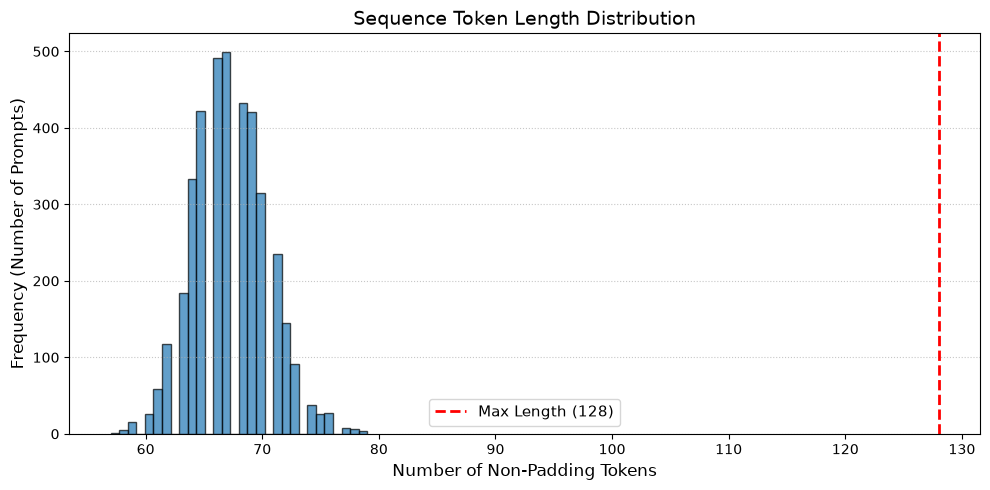

In [33]:
# YOUR CODE HERE
import torch
import matplotlib.pyplot as plt
import numpy as np

# 1. Calculate non-padding token counts for each row
# Summing the attention mask gives the exact count of real (non-padding) tokens
attention_mask = tokenized_dataset['attention_mask']
token_counts = attention_mask.sum(dim=1).numpy()

# 2. Identify truncation risks
max_length_configured = tokenized_dataset['input_ids'].shape[1]
truncated_rows = (token_counts >= max_length_configured).sum()
truncation_pct = (truncated_rows / len(token_counts)) * 100

# 3. Print Statistical Summary
print("--- Token Distribution Analysis ---")
print(f"Total Sequences Analyzed : {len(token_counts)}")
print(f"Configured Max Length    : {max_length_configured}")
print(f"Minimum Token Count      : {token_counts.min()}")
print(f"Mean Token Count         : {token_counts.mean():.2f}")
print(f"Median Token Count       : {np.median(token_counts):.2f}")
print(f"Maximum Token Count      : {token_counts.max()}")
print(f"Truncated Sequences     : {truncated_rows} ({truncation_pct:.2f}%)")

# 4. Check against the 5% threshold requirement
if truncation_pct > 5.0:
    print(f"\n WARNING: {truncation_pct:.2f}% of sequences are truncated (>5% threshold).")
    print("Action Required: Increase MAX_LENGTH in 2.3.1 (e.g., to 256) to prevent cutting off JSON targets.")
else:
    print(f"\nSUCCESS: Only {truncation_pct:.2f}% of sequences hit the max length ceiling (≤ 5% threshold).")
    print("Your target JSON labels are intact and safe for training.")

# 5. Plot the Histogram Distribution
plt.figure(figsize=(10, 5))
plt.hist(token_counts, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(x=max_length_configured, color='red', linestyle='--', linewidth=2, label=f'Max Length ({max_length_configured})')
plt.title("Sequence Token Length Distribution", fontsize=14)
plt.xlabel("Number of Non-Padding Tokens", fontsize=12)
plt.ylabel("Frequency (Number of Prompts)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.tight_layout()
plt.show()

#### **2.3.3 Prepare Retrieval Corpus [3 marks]**
**The Task:** Ingest the Markdown SOPs into LangChain Document objects ready to be embedded.

**Hints & Tips:**
* Use `TextLoader` from LangChain.
* Each `.md` file becomes one `Document` with `.page_content` and `.metadata`.
* These documents are embedded into ChromaDB in Notebook 4.

**Learner Inference:** These document objects form the knowledge base your bot retrieves from in Stages 3 and 4.

In [36]:
import os
import glob

# 1. Print current working directory
print("Current Working Directory:", os.getcwd())

# 2. Search recursively for ANY .md file in the current directory and subdirectories
found_md = glob.glob("**/*.md", recursive=True)

print(f"\nFound {len(found_md)} total .md file(s) across the project:")
for f in found_md[:10]:  # Print first 10 matches
    print(f" -> {f}")

Current Working Directory: /mnt/c/Users/sobcs/Desktop/IITB - Upgrad/New_curriculum/capstone/c97cba9e-beb6-4000-8c0a-50faa9df91cd-Capstone-Implementation-Package/Starter Files

Found 13 total .md file(s) across the project:
 -> Dataset/Dataset/sop_documents/account_recovery.md
 -> Dataset/Dataset/sop_documents/billing_disputes.md
 -> Dataset/Dataset/sop_documents/data_privacy.md
 -> Dataset/Dataset/sop_documents/escalation_matrix.md
 -> Dataset/Dataset/sop_documents/order_tracking.md
 -> Dataset/Dataset/sop_documents/password_reset.md
 -> Dataset/Dataset/sop_documents/payment_methods.md
 -> Dataset/Dataset/sop_documents/product_return.md
 -> Dataset/Dataset/sop_documents/refund_policy.md
 -> Dataset/Dataset/sop_documents/shipping_delays.md


In [39]:
from langchain_community.document_loaders import TextLoader

# 1. Path to the actual nested directory
policy_files = glob.glob("Dataset/Dataset/sop_documents/*.md")
print(f"Found {len(policy_files)} Markdown SOP file(s) in 'Dataset/Dataset/sop_documents/'.")

# 2. Load each Markdown file into a LangChain Document object
documents = []
for file_path in policy_files:
    # TextLoader reads the file content and automatically sets metadata['source'] = file_path
    loader = TextLoader(file_path, encoding='utf-8')
    docs = loader.load()
    documents.extend(docs)

# 3. Print Verification Summary
print(f"\n Successfully loaded {len(documents)} document(s) into LangChain Document objects.")

# 4. Sanity check: Inspect the first loaded document
if len(documents) > 0:
    print("\n--- Sanity Check: First Document Inspection ---")
    print(f"Metadata        : {documents[0].metadata}")
    print(f"Content Length  : {len(documents[0].page_content)} characters")
    print(f"Content Preview :\n{documents[0].page_content[:200]}...")

Found 13 Markdown SOP file(s) in 'Dataset/Dataset/sop_documents/'.

 Successfully loaded 13 document(s) into LangChain Document objects.

--- Sanity Check: First Document Inspection ---
Metadata        : {'source': 'Dataset/Dataset/sop_documents/account_recovery.md'}
Content Length  : 1553 characters
Content Preview :
# Account Recovery

## When To Use
Use this procedure when a customer cannot access their account due to a
lockout, a lost email address, suspected unauthorized access, or a disabled
account — anythin...


### **Task 2.4: Create Dataset Partitions**

#### **2.4.1 Create Train, Validation, and Test Splits [5 marks]**
**The Task:** Split the tokenized dataset into Train (80%), Validation (10%), and Test (10%) partitions using stratified sampling. Demonstrate zero data leakage across all three.

**Hints & Tips:**
* Use `train_test_split` from sklearn with `stratify=df['intent']` so every intent appears in all splits.
* Split twice: first 80/20, then split the 20% into 50/50 (giving 10%/10%).
* The validation set is not optional — it is actively used during fine-tuning (Stage 4 / Notebook 6) for loss monitoring and early stopping.
* The test set must stay completely independent — used only for final evaluation.
* Verify zero overlap with set-intersection checks: `assert len(train_set & test_set) == 0`.
* Build a `df_test` DataFrame preserving readable `text`/`intent`/`category` columns for later scoring.

**Parameter Tuning:**
* Split ratio: `80/10/10` (recommended) or `70/15/15`. Any alternative must be justified.

**Why we are doing it:** To guarantee isolated, unseen data for unbiased evaluation, and a validation set for overfitting detection.
**How we are doing it:** Stratified sklearn splits with explicit programmatic leakage verification.

**Learner Inference:** Testing on data the model trained on gives false confidence (leakage). The held-out test split proves your model handles completely new phrasing; the validation split tells you when to stop training.

In [41]:
# YOUR CODE HERE
from sklearn.model_selection import train_test_split

# Assume `df_clean` is your cleaned pandas DataFrame with 'formatted_text', 'intent', and 'category' columns
# Assume `tokenized_dataset` is your dictionary containing 'input_ids', 'attention_mask', and 'labels' tensors

# -------------------------------------------------------------------------
# Step 1: Perform Stratified Splits on DataFrame Indices
# -------------------------------------------------------------------------
indices = list(range(len(df_clean)))

# First split: 80% Train, 20% Temp (Val + Test)
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=df_clean['intent']
)

# Second split: Split the 20% Temp equally (50% Val, 50% Test) -> 10% Val, 10% Test overall
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=df_clean.iloc[temp_idx]['intent']
)

# -------------------------------------------------------------------------
# Step 2: Slice DataFrames and Tensors into Partition Sets
# -------------------------------------------------------------------------
# Create DataFrames
df_train = df_clean.iloc[train_idx].reset_index(drop=True)
df_val   = df_clean.iloc[val_idx].reset_index(drop=True)
df_test  = df_clean.iloc[test_idx].reset_index(drop=True)  # Preserves human-readable columns for scoring

# Slice PyTorch Tensor Dictionary
def slice_tensor_dict(tensor_dict, idx_list):
    idx_tensor = torch.tensor(idx_list, dtype=torch.long)
    return {
        'input_ids': tensor_dict['input_ids'][idx_tensor],
        'attention_mask': tensor_dict['attention_mask'][idx_tensor],
        'labels': tensor_dict['labels'][idx_tensor]
    }

train_tensors = slice_tensor_dict(tokenized_dataset, train_idx)
val_tensors   = slice_tensor_dict(tokenized_dataset, val_idx)
test_tensors  = slice_tensor_dict(tokenized_dataset, test_idx)

# -------------------------------------------------------------------------
# Step 3: Explicit Programmatic Data Leakage Checks
# -------------------------------------------------------------------------
train_set_idx = set(train_idx)
val_set_idx   = set(val_idx)
test_set_idx  = set(test_idx)

# Check 1: Index Overlap
overlap_train_val  = len(train_set_idx & val_set_idx)
overlap_train_test = len(train_set_idx & test_set_idx)
overlap_val_test   = len(val_set_idx & test_set_idx)

# Check 2: Formatted Text String Overlap
train_texts = set(df_train['formatted_text'])
val_texts   = set(df_val['formatted_text'])
test_texts  = set(df_test['formatted_text'])

text_overlap_train_test = len(train_texts & test_texts)

# Programmatic Assertions
assert overlap_train_val == 0, " Data Leakage Detected: Train and Val index overlap!"
assert overlap_train_test == 0, " Data Leakage Detected: Train and Test index overlap!"
assert overlap_val_test == 0, " Data Leakage Detected: Val and Test index overlap!"

print("--- 1. Data Split & Partitioning Summary ---")
total_rows = len(df_clean)
print(f"Total Dataset Size : {total_rows}")
print(f"Train Partition    : {len(df_train)} samples ({len(df_train)/total_rows*100:.1f}%)")
print(f"Val Partition      : {len(df_val)} samples ({len(df_val)/total_rows*100:.1f}%)")
print(f"Test Partition     : {len(df_test)} samples ({len(df_test)/total_rows*100:.1f}%)")

print("\n--- 2. Programmatic Zero-Leakage Verification ---")
print(f"Index Overlap (Train ∩ Val)  : {overlap_train_val}")
print(f"Index Overlap (Train ∩ Test) : {overlap_train_test}")
print(f"Index Overlap (Val ∩ Test)   : {overlap_val_test}")
print(f"Text Overlap  (Train ∩ Test) : {text_overlap_train_test}")
print("\n SUCCESS: Zero data leakage confirmed across all 3 partitions!")

print("\n--- 3. Target Data Frame Check (df_test preserved) ---")
print("Preserved columns in df_test:", list(df_test.columns))

--- 1. Data Split & Partitioning Summary ---
Total Dataset Size : 3902
Train Partition    : 3121 samples (80.0%)
Val Partition      : 390 samples (10.0%)
Test Partition     : 391 samples (10.0%)

--- 2. Programmatic Zero-Leakage Verification ---
Index Overlap (Train ∩ Val)  : 0
Index Overlap (Train ∩ Test) : 0
Index Overlap (Val ∩ Test)   : 0
Text Overlap  (Train ∩ Test) : 0

 SUCCESS: Zero data leakage confirmed across all 3 partitions!

--- 3. Target Data Frame Check (df_test preserved) ---
Preserved columns in df_test: ['flags', 'instruction', 'category', 'intent', 'response', 'formatted_text']


---
## Save Artifacts for Downstream Notebooks

**IMPORTANT:** These cells save all datasets. Notebooks 5, 6, and 7 depend on them.

In [44]:
# YOUR CODE HERE
import os
import pandas as pd
from datasets import Dataset

# Define output file paths
TRAIN_DIR = "./tokenized_train"
VALID_DIR = "./tokenized_valid"
TEST_DIR  = "./tokenized_test"
TEST_CSV_PATH = "df_test.csv"

# -------------------------------------------------------------------------
# Step 1: Convert PyTorch Tensor Dicts into HuggingFace Datasets
# -------------------------------------------------------------------------
# `train_tensors`, `val_tensors`, and `test_tensors` are dicts with keys:
# ['input_ids', 'attention_mask', 'labels']
hf_train_dataset = Dataset.from_dict({
    'input_ids': train_tensors['input_ids'].tolist(),
    'attention_mask': train_tensors['attention_mask'].tolist(),
    'labels': train_tensors['labels'].tolist()
})

hf_valid_dataset = Dataset.from_dict({
    'input_ids': val_tensors['input_ids'].tolist(),
    'attention_mask': val_tensors['attention_mask'].tolist(),
    'labels': val_tensors['labels'].tolist()
})

hf_test_dataset = Dataset.from_dict({
    'input_ids': test_tensors['input_ids'].tolist(),
    'attention_mask': test_tensors['attention_mask'].tolist(),
    'labels': test_tensors['labels'].tolist()
})

# -------------------------------------------------------------------------
# Step 2: Save HuggingFace Datasets to Disk (Required by NB6)
# -------------------------------------------------------------------------
hf_train_dataset.save_to_disk(TRAIN_DIR)
hf_valid_dataset.save_to_disk(VALID_DIR)
hf_test_dataset.save_to_disk(TEST_DIR)

print(f" Saved HuggingFace Train dataset to : {TRAIN_DIR}")
print(f" Saved HuggingFace Valid dataset to : {VALID_DIR}")
print(f" Saved HuggingFace Test dataset to  : {TEST_DIR}")

# -------------------------------------------------------------------------
# Step 3: Save df_test.csv with Readable Text & Labels (Required by NB5 & NB7)
# -------------------------------------------------------------------------
# Save without the pandas auto-generated integer index column
df_test.to_csv(TEST_CSV_PATH, index=False)
print(f" Saved human-readable Test DataFrame to : {TEST_CSV_PATH}")

# -------------------------------------------------------------------------
# Step 4: Verification Check
# -------------------------------------------------------------------------
print("\n--- Disk Export Verification Summary ---")
assert os.path.exists(TRAIN_DIR), " Missing tokenized_train directory"
assert os.path.exists(VALID_DIR), " Missing tokenized_valid directory"
assert os.path.exists(TEST_DIR),  " Missing tokenized_test directory"
assert os.path.exists(TEST_CSV_PATH), " Missing df_test.csv"

print(f" Success! All artifacts exported successfully.")
print(f"  - Train rows : {len(hf_train_dataset)}")
print(f"  - Valid rows : {len(hf_valid_dataset)}")
print(f"  - Test rows  : {len(hf_test_dataset)}")
print(f"  - df_test CSV shape : {df_test.shape}")

Saving the dataset (1/1 shards): 100%|██████████████████████████████████████| 391/391 [00:00<00:00, 17454.32 examples/s]

 Saved HuggingFace Train dataset to : ./tokenized_train
 Saved HuggingFace Valid dataset to : ./tokenized_valid
 Saved HuggingFace Test dataset to  : ./tokenized_test
 Saved human-readable Test DataFrame to : df_test.csv

--- Disk Export Verification Summary ---
 Success! All artifacts exported successfully.
  - Train rows : 3121
  - Valid rows : 390
  - Test rows  : 391
  - df_test CSV shape : (391, 6)


---
## END-OF-NOTEBOOK CHECKLIST

> **IMPORTANT: Verify all items before proceeding to Notebook 3.**

- [ ] `sampled_data.csv` loaded
- [ ] **Duplicates + invalid records removed (normalised dedup)** ← _Task 2.1.1_
- [ ] Data standardised (intent=lower, category=UPPER)
- [ ] ChatML formatting applied and validated (valid JSON)
- [ ] Tokenization completed with `-100` label masking
- [ ] Token distribution analysed — truncation risk assessed
- [ ] Retrieval corpus loaded from `.md` files
- [ ] **Stratified Train/Valid/Test split** with all intents in every partition
- [ ] **Zero leakage verified** via set-intersection checks
- [ ] **`./tokenized_train/` + `./tokenized_valid/` saved** ← _CRITICAL for NB6_
- [ ] **`df_test.csv` saved** ← _CRITICAL for NB5 and NB7_

**If any item is unchecked, fix it before moving on.**